# NASA Space Apps 2026 - Health Monitor EDA

**Goal:** Consume the official data endpoint of the *NASA Life Sciences Portal (NLSP)* (`/api/v1/data/experiments`), structure the experiment metadata and classify it into the **5 NASA Hazards** and the **body systems** to select the scientific base of the Health Monitor.

### Pipeline structure
1. **Setup and configuration:** imports and API constants.
2. **Paginated extraction and cache (`NLSPDataClient`):** automated collection from `https://nlsp.nasa.gov/api/v1/data/experiments` with local persistence.
3. **Cleaning and normalization:** nested lists, merged biomarkers (`parameter_name` + `AssayMeasurements`) and HTML parsing.
4. **Categorization (5 Hazards & human body systems):** rule engine over research areas, keywords and variables.
5. **Exploratory analysis (EDA) of the metadata:** study distribution, Hazard x organ matrix and top monitorable biomarkers.
6. **Ranking and export:** selection of the best studies for deeper review and generation of clean datasets (`.csv` and `.json`).

---
## 1. Setup and configuration
We define the packages used and the URL of the data endpoint we found.

In [7]:
import requests
import pandas as pd
import json
import re
import time
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

EXPERIMENTS_ENDPOINT = "https://nlsp.nasa.gov/api/v1/data/experiments"
CACHE_FILE = Path("nlsp_experiments_cache.json")

---
## 2. Paginated extraction client and local cache
The endpoint accepts the parameters `sortBy=dateAdded_desc`, `page`, `limit` and `view=table`, and returns an object with a `documents` key and pagination metadata (`total`, `page`, `limit`, `totalPages`).

The class below handles pagination, waits a short interval (`delay`) between calls to avoid being blocked, and saves the result locally.

In [8]:
class NLSPDataClient:
    def __init__(self, endpoint=EXPERIMENTS_ENDPOINT):
        self.endpoint = endpoint
        self.session = requests.Session()
        self.session.headers.update({
            "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36",
            "Accept": "application/json"
        })

    def fetch_page(self, page=1, limit=25, sort_by="dateAdded_desc", view="table", extra_params=None):
        """Busca uma única página do endpoint /api/v1/data/experiments."""
        params = {
            "sortBy": sort_by,
            "page": page,
            "limit": limit,
            "view": view
        }
        if extra_params:
            params.update(extra_params)

        response = self.session.get(self.endpoint, params=params, timeout=20)
        response.raise_for_status()
        return response.json()

    def fetch_experiments(self, max_pages=10, limit=100, delay=0.4, use_cache=True, cache_path=CACHE_FILE):
        """
        Coleta múltiplas páginas da API ou carrega do cache local caso já exista.
        Dica: Defina max_pages=None para baixar absolutamente todas as páginas disponíveis.
        """
        if use_cache and cache_path.exists():
            with open(cache_path, "r", encoding="utf-8") as f:
                cached_docs = json.load(f)
            print(f"[Cache] {len(cached_docs)} experimentos carregados de '{cache_path}'.")
            return cached_docs

        all_documents = []
        page = 1

        while True:
            try:
                payload = self.fetch_page(page=page, limit=limit)
                docs = payload.get("documents", [])
                total = payload.get("total", 0)
                total_pages = payload.get("totalPages", 1)

                if not docs:
                    break

                all_documents.extend(docs)
                print(f"Página {page}/{total_pages} | +{len(docs)} registros (Acumulado: {len(all_documents)}/{total})")

                if page >= total_pages or (max_pages is not None and page >= max_pages):
                    break

                page += 1
                time.sleep(delay)

            except Exception as e:
                print(f"Erro ao coletar página {page}: {e}")
                break

        if all_documents and cache_path:
            with open(cache_path, "w", encoding="utf-8") as f:
                json.dump(all_documents, f, ensure_ascii=False, indent=2)
            print(f"[Cache] {len(all_documents)} experimentos salvos em '{cache_path}'.")

        return all_documents

client = NLSPDataClient()
# Fetch the first 10 pages with limit=100 (up to 1000 studies).
# To fetch all ~2676 studies, set max_pages=None.
raw_documents = client.fetch_experiments(max_pages=10, limit=100, use_cache=True)

[Cache] 1000 experimentos carregados de 'nlsp_experiments_cache.json'.


---
## 3. Metadata cleaning and normalization pipeline
The documents returned by the endpoint have important variations, handled below:
* **Nested lists:** fields such as `CombinedSpecies` and `missions` alternate between flat lists `['Ground']` and triple-nested lists `[[['Expedition 35']]]`.
* **Biomarkers and variables:** we merge `parameter_name`, `AssayMeasurements` and `StudyFactors`, dropping placeholders such as `'experiment_parms'` or `'None'`.
* **HTML parsing:** we strip HTML tags from `experiment_description` and split the text into `objectives`, `approach` and `results`.

In [9]:
def flatten_clean(val):
    """Desaninha listas de qualquer profundidade e remove valores vazios ou duplicados."""
    if val is None:
        return []
    if isinstance(val, (str, int, float)):
        s = str(val).strip()
        return [s] if s and s.lower() not in ["none", "null", "n/a", "experiment_parms"] else []
    
    result = []
    if isinstance(val, list):
        for item in val:
            result.extend(flatten_clean(item))
    return list(dict.fromkeys(result))

def strip_html(html_text):
    """Remove tags HTML e espaços extras."""
    if not html_text or not isinstance(html_text, str):
        return ""
    text = re.sub(r'<[^>]+>', ' ', html_text)
    return re.sub(r'\s+', ' ', text).strip()

def parse_description_sections(raw_html):
    """Extrai Objectives, Approach e Results de dentro de experiment_description."""
    clean = strip_html(raw_html)
    obj_match = re.search(r"OBJECTIVES?:?\s*(.*?)\s*(?:APPROACH:?|RESULTS?:?|$)", clean, re.IGNORECASE)
    app_match = re.search(r"APPROACH:?\s*(.*?)\s*(?:OBJECTIVES?:?|RESULTS?:?|$)", clean, re.IGNORECASE)
    res_match = re.search(r"RESULTS?:?\s*(.*)", clean, re.IGNORECASE)
    
    return (
        obj_match.group(1).strip() if obj_match else clean[:500],
        app_match.group(1).strip() if app_match else "",
        res_match.group(1).strip() if res_match else ""
    )

def build_experiments_dataframe(documents):
    """Converte a lista de dicionários da API em um DataFrame padronizado."""
    records = []
    for doc in documents:
        species = flatten_clean(doc.get("CombinedSpecies")) or flatten_clean(doc.get("species"))
        is_human = any("human" in s.lower() or "homo sapiens" in s.lower() for s in species)
        
        # Merge every source of variables measured in the experiment
        variables = list(dict.fromkeys(
            flatten_clean(doc.get("parameter_name")) +
            flatten_clean(doc.get("AssayMeasurements")) +
            flatten_clean(doc.get("StudyFactors"))
        ))
        
        objectives, approach, results = parse_description_sections(doc.get("experiment_description", ""))
        archive_status = str(doc.get("archive_status", ""))
        
        records.append({
            "id": doc.get("id"),
            "experiment_id": doc.get("experiment_id"),
            "title": doc.get("experiment_title", ""),
            "doi": doc.get("__doi", ""),
            "program": flatten_clean(doc.get("Program")) or flatten_clean(doc.get("program_name")),
            "experiment_type": flatten_clean(doc.get("experiment_type_lk")) or flatten_clean(doc.get("experiment_type")),
            "missions": flatten_clean(doc.get("missions")),
            "center": flatten_clean(doc.get("center")) or flatten_clean(doc.get("nasa_center")),
            "species": species,
            "is_human": is_human,
            "research_area": flatten_clean(doc.get("research_area")),
            "keywords": flatten_clean(doc.get("keyword")),
            "variables": variables,
            "num_variables": len(variables),
            "archive_status": archive_status,
            "is_public_data": "publicly available" in archive_status.lower(),
            "has_results": len(results) > 40 and "experiment is in progress" not in results.lower(),
            "objectives": objectives,
            "approach": approach,
            "results": results
        })
        
    return pd.DataFrame(records)

df_experiments = build_experiments_dataframe(raw_documents)
print(f"DataFrame construído: {len(df_experiments)} experimentos | {df_experiments['is_human'].sum()} envolvendo humanos.")
df_experiments.head(3)

DataFrame construído: 1000 experimentos | 755 envolvendo humanos.


,id,experiment_id,title,doi,program,experiment_type,missions,center,species,is_human,research_area,keywords,variables,num_variables,archive_status,is_public_data,has_results,objectives,approach,results
0,2d2d3169-478b-5369-bba0-15caca237fee,NNX12AR15G,Monitoring and Regulating Teamwork,10.83263/km9v-pj06,[Ground],[NASA Ground-Based Investigations],[Ground],[Johnson Space Center],[Human (Homo sapiens)],True,[Behavior and performance],"[Task performance and analysis, Affect, Adaptation, psychological, Conflict, Work, Adaptation, p...","[Adaptability, Affect, Anxiety, Coordination, Face time, Heart rate, Heart rate variability, Per...",17,Data preservation is complete. All datasets are privacy-protected. Data is available via data re...,False,True,Collaboration and cohesion are critical underpinnings of teamwork. This is especially true for h...,The methodology is embedded in the,below. RESULTS: LD Benchmarking Data for ICE Teams Overview. The first specific aim for the proj...
1,df9b9d0d-ae9f-54d0-912e-9bec1e64ee37,NNX12AB55G,Molecular and Cellular Mechanisms of Space Radiation-Induced Changes in Hippocampal-Dependent Be...,10.83263/e6eb-0h64,[Ground],[NASA Ground-Based Investigations],[Ground],[Johnson Space Center],[Mouse (Mus musculus)],False,[Radiation biology],"[Cosmic radiation, Cell count, Risk assessment, Linear energy transfer (LET), Time factors, Hipp...","[Age, Context discrimination fear conditioning (CDFC), Contextual fear conditioning (CFC), Dark ...",8,Data preservation is complete. All datasets are privacy-protected. Data is available via data re...,False,False,An unavoidable consequence of many space missions is exposure to galactic cosmic radiation (GCR)...,"es to answer key remaining questions about how space radiation influences the cellular, molecula...","This experiment is in progress. However, preliminary results are available. Aim 1: Determine the..."
2,6f350cc6-730b-5f11-98ef-680fd865f4c7,Spinal_Ultrasound,Sonographic Astronaut Vertebral Examination,10.83263/vtvg-fc92,[International Space Station (ISS)],[International Space Station (ISS)],"[Expedition 35, Expedition 36, Expedition 37, Expedition 38, Expedition 33, Expedition 34]",[Johnson Space Center],[Human (Homo sapiens)],True,"[Skeletal physiology, Muscle physiology]","[Cross-sectional area (CSA), Spine, Musculoskeletal physiology, Ultrasonography]","[Bone area, Cartilage metabolism biomarkers, Cartilage thickness, Cartilage volume, Cerebrospina...",22,Data preservation is complete. All datasets are privacy-protected. Data is available via data re...,False,True,"This study provided longitudinal, real-time data regarding adaptation of the vertebral unit duri...",Preflight baseline data collection (BDC) sessions consisted of a cervical and lumbosacral verteb...,Ultrasound correlated well with preflight and post flight MRI examinations. Investigators demons...


---
## 4. Categorization into the 5 Hazards and body systems
We cross `research_area`, `keywords`, `variables` and `title` to map each study into:
* **5 NASA Hazards:** *Space Radiation*, *Isolation and Confinement*, *Distance from Earth*, *Gravity Fields*, *Hostile Closed Environments*.
* **Human body systems (monitor avatar):** *Brain & Behavioral*, *Ocular & Vision*, *Cardiovascular & Fluids*, *Musculoskeletal*, *Immune, Lungs & Cellular*.

In [10]:
HAZARD_TAXONOMY = {
    "Space Radiation": {
        "areas": {"Radiation biology"},
        "terms": ["radiation", "hze", "cosmic", "galactic", "solar particle", "linear energy transfer", "dosimetry", "dna damage", "irradiat", "radiobiology"]
    },
    "Isolation and Confinement": {
        "areas": {"Behavior and performance", "Human factors"},
        "terms": ["isolation", "confined", "confinement", "ice ", "cohesion", "sleep", "circadian", "stress", "anxiety", "mood", "teamwork", "journal", "hera", "hi-seas", "fatigue"]
    },
    "Distance from Earth": {
        "areas": {"Clinical medicine"},
        "terms": ["autonom", "communication delay", "multi-team", "self-guided", "telemedicine", "evacuation", "long-duration exploration", "medical care"]
    },
    "Gravity Fields": {
        "areas": {"Skeletal physiology", "Muscle physiology", "Cardiovascular physiology", "Ocular physiological phenomena", "Exercise physiology", "Renal, fluid and electrolyte physiology"},
        "terms": ["microgravity", "weightlessness", "bed rest", "bedrest", "fluid shift", "intracranial pressure", "viip", "sans", "bone", "vertebral", "muscle", "vestibular", "doppler", "orthostatic", "head-down tilt"]
    },
    "Hostile Closed Environments": {
        "areas": {"Immunology", "Microbiology", "Environmental monitoring", "Life support systems"},
        "terms": ["immune", "immunity", "virus", "herpes", "ebv", "cmv", "cytokine", "lymphocyte", "t cell", "microbiome", "cabin", "co2", "acoustic", "air quality", "water"]
    }
}

ANATOMICAL_SYSTEMS = {
    "Brain & Behavioral": {
        "areas": {"Behavior and performance", "Neuroscience", "Human factors"},
        "terms": ["sleep", "anxiety", "cognitive", "hippocamp", "cerebral", "stress", "cohesion", "neuron", "vestibular", "mood", "reaction time", "workload"]
    },
    "Ocular & Vision": {
        "areas": {"Ocular physiological phenomena"},
        "terms": ["optic", "retina", "intraocular", "visual", "cornea", "papilledema", "viip", "sans", "eye", "macula", "choroid"]
    },
    "Cardiovascular & Fluids": {
        "areas": {"Cardiovascular physiology", "Renal, fluid and electrolyte physiology"},
        "terms": ["heart rate", "blood pressure", "carotid", "jugular", "vascular", "echocardiography", "fluid shift", "microvessel", "plasma volume", "artery", "vein"]
    },
    "Musculoskeletal": {
        "areas": {"Skeletal physiology", "Muscle physiology", "Exercise physiology"},
        "terms": ["bone", "muscle", "vertebral", "cartilage", "spine", "disc", "atrophy", "dexa", "lumbar", "cervical", "calcium"]
    },
    "Immune, Lungs & Cellular": {
        "areas": {"Immunology", "Microbiology", "Cell and molecular biology", "Radiation biology"},
        "terms": ["t cell", "nk cell", "leukocyte", "dna damage", "lung", "tumor", "cytokine", "virus", "cortisol", "alpha-amylase", "interleukin", "gene expression"]
    }
}

def map_hazards_and_anatomy(row):
    row_areas = set(row["research_area"])
    corpus = " ".join([
        row["title"],
        " ".join(row["keywords"]),
        " ".join(row["variables"]),
        row["objectives"][:400]
    ]).lower()

    hazards = [
        h for h, cfg in HAZARD_TAXONOMY.items()
        if (row_areas & cfg["areas"]) or any(t in corpus for t in cfg["terms"])
    ]
    systems = [
        s for s, cfg in ANATOMICAL_SYSTEMS.items()
        if (row_areas & cfg["areas"]) or any(t in corpus for t in cfg["terms"])
    ]

    return pd.Series([
        hazards if hazards else ["Unclassified"],
        systems if systems else ["Systemic / Other"]
    ], index=["hazards", "body_systems"])

df_experiments[["hazards", "body_systems"]] = df_experiments.apply(map_hazards_and_anatomy, axis=1)
df_human = df_experiments[df_experiments["is_human"]].copy()
print("Classificação concluída!")

Classificação concluída!


---
## 5. Exploratory analysis of the metadata (EDA)
We plot the distribution of human studies by Hazard and by body system, and identify the most frequent biomarkers (`variables`) for each risk.

In [11]:
print("=== 1. QUANTIDADE DE ESTUDOS (HUMANOS vs GERAL) POR HAZARD ===")
haz_all = df_experiments.explode("hazards")["hazards"].value_counts().rename("Total_Estudos")
haz_hum = df_human.explode("hazards")["hazards"].value_counts().rename("Estudos_Humanos")
haz_pub = df_human[df_human["is_public_data"]].explode("hazards")["hazards"].value_counts().rename("Humanos_Dados_Publicos")
display(pd.concat([haz_all, haz_hum, haz_pub], axis=1).fillna(0).astype(int))

print("\n=== 2. MATRIZ DE INTERSEÇÃO: HAZARD x SISTEMA ANATÔMICO (APENAS HUMANOS) ===")
df_exp_matrix = df_human.explode("hazards").explode("body_systems")
matrix = pd.crosstab(df_exp_matrix["hazards"], df_exp_matrix["body_systems"], margins=True)
display(matrix)

print("\n=== 3. TOP 8 BIOMARCADORES / VARIÁVEIS MEDIDAS POR HAZARD (HUMANOS) ===")
df_vars = df_human.explode("hazards").explode("variables").dropna(subset=["variables"])
top_vars_per_hazard = (
    df_vars.groupby(["hazards", "variables"])
    .size()
    .reset_index(name="freq")
    .sort_values(["hazards", "freq"], ascending=[True, False])
    .groupby("hazards")
    .head(8)
)
display(top_vars_per_hazard)

=== 1. QUANTIDADE DE ESTUDOS (HUMANOS vs GERAL) POR HAZARD ===


,Total_Estudos,Estudos_Humanos,Humanos_Dados_Publicos
hazards,,,
Gravity Fields,569,415,167
Isolation and Confinement,352,291,89
Hostile Closed Environments,276,187,77
Distance from Earth,145,140,69
Space Radiation,140,85,26
Unclassified,53,41,16



=== 2. MATRIZ DE INTERSEÇÃO: HAZARD x SISTEMA ANATÔMICO (APENAS HUMANOS) ===


body_systems,Brain & Behavioral,Cardiovascular & Fluids,"Immune, Lungs & Cellular",Musculoskeletal,Ocular & Vision,Systemic / Other,All
hazards,,,,,,,
Distance from Earth,54,54,22,30,17,27,204
Gravity Fields,152,182,68,211,71,12,696
Hostile Closed Environments,51,55,105,58,9,25,303
Isolation and Confinement,220,86,57,70,36,7,476
Space Radiation,13,5,74,8,8,6,114
Unclassified,15,5,7,6,9,14,56
All,505,387,333,383,150,91,1849



=== 3. TOP 8 BIOMARCADORES / VARIÁVEIS MEDIDAS POR HAZARD (HUMANOS) ===


,hazards,variables,freq
531,Distance from Earth,Heart rate,21
336,Distance from Earth,Diastolic blood pressure,17
119,Distance from Earth,Blood pressure,16
1187,Distance from Earth,Systolic blood pressure,15
994,Distance from Earth,Respiration rate,9
1211,Distance from Earth,Team performance,8
85,Distance from Earth,Autonomy,7
133,Distance from Earth,Body weight,7
3292,Gravity Fields,Heart rate,89
1851,Gravity Fields,Blood pressure,45


---
## 6. Study prioritization and export
Not every NLSP study is equally useful for building the monitor right away. We create a `relevance_score` that ranks higher the experiments that:
1. Are performed on **humans** (+30 pts)
2. Have **open public data** instead of restricted data (+25 pts)
3. Have consolidated **results** text (+20 pts)
4. Map **explicit biomarkers** (+2 pts per variable, up to 20 pts)
5. Were conducted on the **ISS or in spaceflight** (+5 pts)

In [12]:
def compute_relevance_score(row):
    score = 0
    if row["is_human"]:
        score += 30
    if row["is_public_data"]:
        score += 25
    if row["has_results"]:
        score += 20
    score += min(row["num_variables"] * 2, 20)
    if any("international space station" in p.lower() or "shuttle" in p.lower() for p in row["program"]):
        score += 5
    return score

df_experiments["relevance_score"] = df_experiments.apply(compute_relevance_score, axis=1)
df_ranked = df_experiments.sort_values("relevance_score", ascending=False)

print("=== TOP 5 ESTUDOS CANDIDATOS POR HAZARD PARA APROFUNDAMENTO ===")
top_candidates = (
    df_ranked[df_ranked["is_human"]]
    .explode("hazards")
    .groupby("hazards")
    .head(5)[["hazards", "experiment_id", "title", "relevance_score", "is_public_data", "num_variables", "body_systems", "doi"]]
)
display(top_candidates)

# Export the categorized dataset to CSV and JSON (ready for the team)
df_ranked.to_csv("nlsp_categorized_experiments.csv", index=False)
df_ranked[df_ranked["is_human"]].to_json("nlsp_human_monitor_catalog.json", orient="records", indent=2)
print("\nArquivos 'nlsp_categorized_experiments.csv' e 'nlsp_human_monitor_catalog.json' gerados com sucesso!")

=== TOP 5 ESTUDOS CANDIDATOS POR HAZARD PARA APROFUNDAMENTO ===


,hazards,experiment_id,title,relevance_score,is_public_data,num_variables,body_systems,doi
23,Gravity Fields,DSO 470,The Relationship of Space Adaptation Syndrome to Middle Cerebral Artery Blood Velocity Measured ...,100,True,12,"[Brain & Behavioral, Cardiovascular & Fluids]",10.83263/ycac-pj81
18,Isolation and Confinement,ILSRA-2001-104,Behavioral Issues Associated with Long Duration Space Missions: Review of Astronaut Journals,100,True,10,[Brain & Behavioral],10.83263/w7m8-qf96
241,Distance from Earth,DSO 624,Pre- and Postflight Measurement of Cardiorespiratory Responses to Submaximal Exercise,100,True,15,"[Cardiovascular & Fluids, Musculoskeletal]",10.83263/wjse-8a69
241,Gravity Fields,DSO 624,Pre- and Postflight Measurement of Cardiorespiratory Responses to Submaximal Exercise,100,True,15,"[Cardiovascular & Fluids, Musculoskeletal]",10.83263/wjse-8a69
241,Hostile Closed Environments,DSO 624,Pre- and Postflight Measurement of Cardiorespiratory Responses to Submaximal Exercise,100,True,15,"[Cardiovascular & Fluids, Musculoskeletal]",10.83263/wjse-8a69
494,Gravity Fields,96-E057,Renal Stone Risk During Space Flight: Assessment and Countermeasure Validation,100,True,19,"[Cardiovascular & Fluids, Musculoskeletal]",10.83263/zdb3-4841
509,Distance from Earth,DSO 476,Inflight Aerobic Exercise,100,True,15,"[Cardiovascular & Fluids, Musculoskeletal]",10.83263/207b-nj31
509,Gravity Fields,DSO 476,Inflight Aerobic Exercise,100,True,15,"[Cardiovascular & Fluids, Musculoskeletal]",10.83263/207b-nj31
840,Gravity Fields,DSO 477,The Evaluation of Concentric and Eccentric Skeletal Muscle Contractions Following Space Flight,100,True,18,[Musculoskeletal],10.83263/4z2b-w149
781,Space Radiation,SMO_Stability_Pharm,Stability of Pharmacotherapeutic Compounds,100,True,43,[Systemic / Other],10.83263/2t39-cw20



Arquivos 'nlsp_categorized_experiments.csv' e 'nlsp_human_monitor_catalog.json' gerados com sucesso!


# Chart by topic.

C:\Users\nb1_l\AppData\Local\Temp\ipykernel_21440\1273807996.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_plot_hazards, x="Quantidade", y="Hazard", palette="viridis")


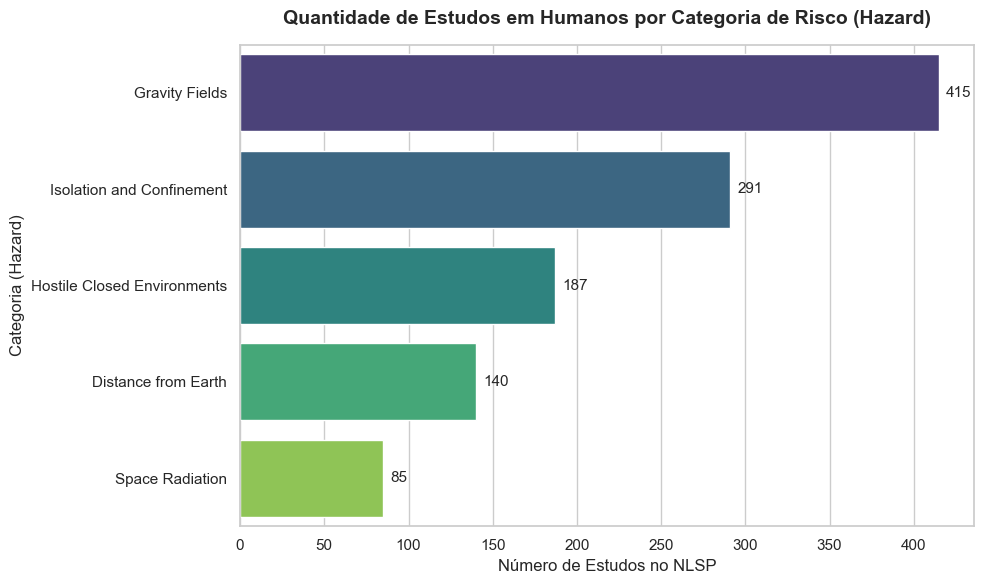

In [13]:
# Install seaborn if needed: !pip install seaborn matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Visual style
sns.set_theme(style="whitegrid")

# Prepare the data: explode the hazard list to count each occurrence
df_plot_hazards = df_human.explode("hazards")["hazards"].value_counts().reset_index()
df_plot_hazards.columns = ["Hazard", "Quantidade"]

# Drop the "Unclassified" category if present, to focus on the main 5
df_plot_hazards = df_plot_hazards[df_plot_hazards["Hazard"] != "Unclassified"]

# Build the chart
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df_plot_hazards, x="Quantidade", y="Hazard", palette="viridis")

# Add numeric labels to each bar
for i in ax.containers:
    ax.bar_label(i, padding=5, fontsize=11)

plt.title("Quantidade de Estudos em Humanos por Categoria de Risco (Hazard)", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Número de Estudos no NLSP", fontsize=12)
plt.ylabel("Categoria (Hazard)", fontsize=12)
plt.tight_layout()
plt.show()

# Recurrence chart by hazard

C:\Users\nb1_l\AppData\Local\Temp\ipykernel_21440\2117524134.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_vars, x="Frequência", y="Biomarcador / Variável", palette="mako")


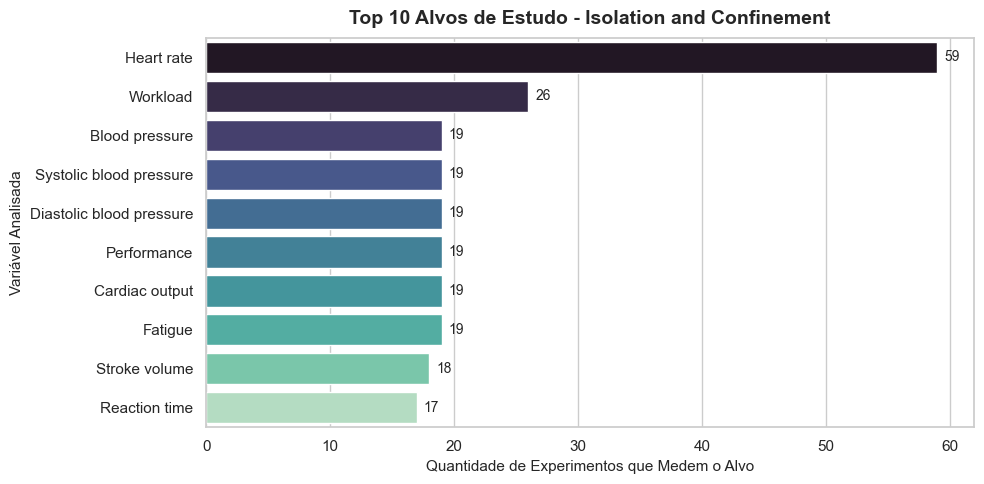

C:\Users\nb1_l\AppData\Local\Temp\ipykernel_21440\2117524134.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_vars, x="Frequência", y="Biomarcador / Variável", palette="mako")


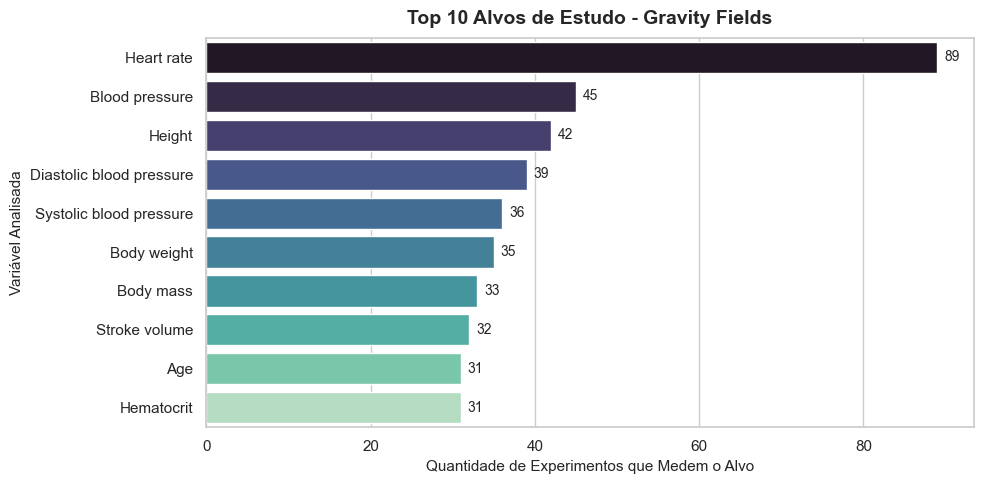

C:\Users\nb1_l\AppData\Local\Temp\ipykernel_21440\2117524134.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_vars, x="Frequência", y="Biomarcador / Variável", palette="mako")


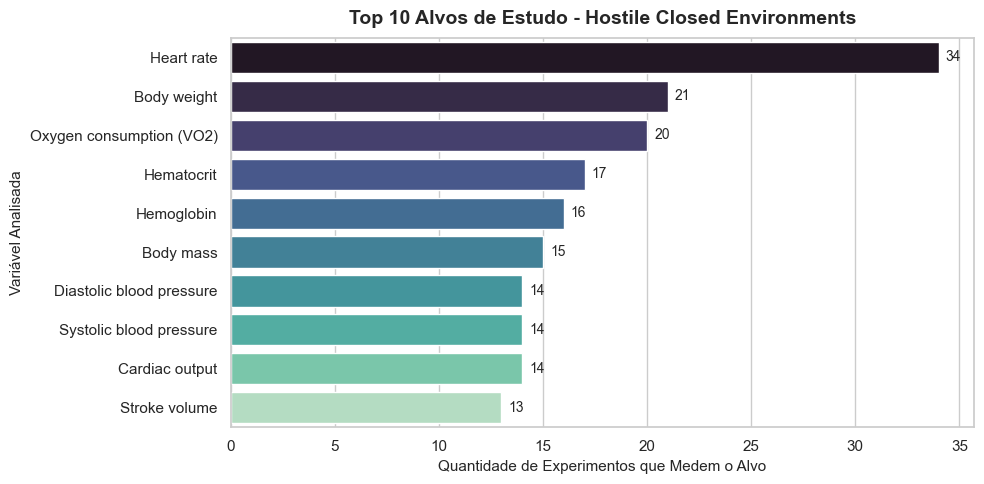

C:\Users\nb1_l\AppData\Local\Temp\ipykernel_21440\2117524134.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_vars, x="Frequência", y="Biomarcador / Variável", palette="mako")


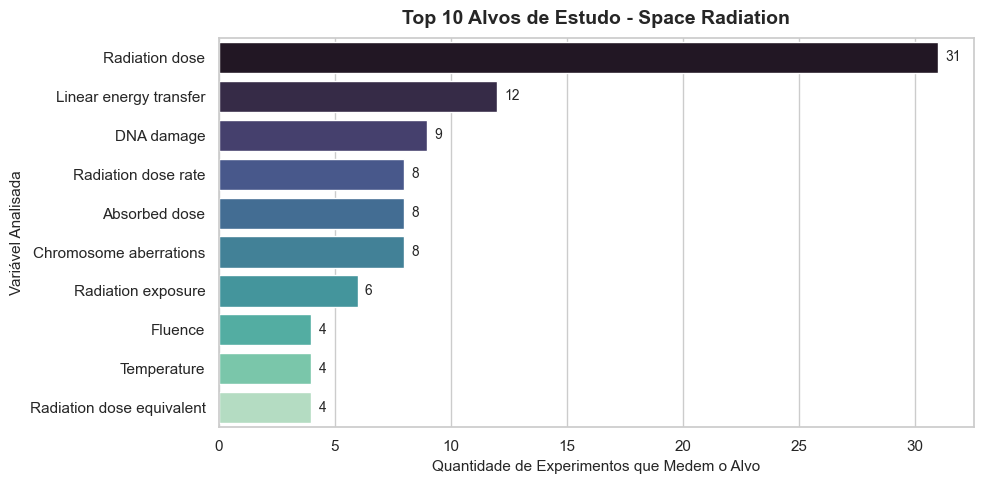

C:\Users\nb1_l\AppData\Local\Temp\ipykernel_21440\2117524134.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_vars, x="Frequência", y="Biomarcador / Variável", palette="mako")


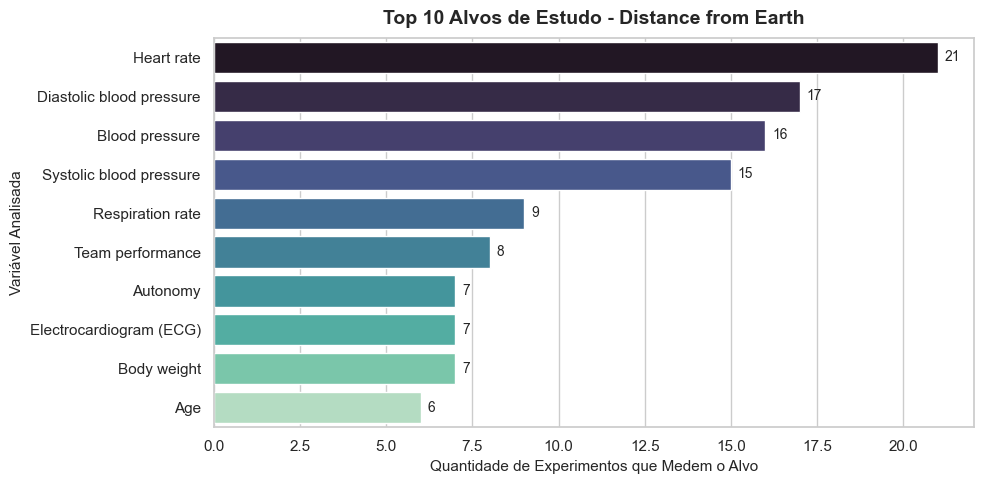

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Explicitly define the project's 5 target Hazards
target_hazards = [
    "Space Radiation", 
    "Isolation and Confinement", 
    "Distance from Earth", 
    "Gravity Fields", 
    "Hostile Closed Environments"
]

# Keep ONLY human studies with public (open) data
df_public = df_human[df_human["is_public_data"] == True].copy()
print(f"Total de estudos em humanos com DADOS PÚBLICOS analisados: {len(df_public)}\n")

# Prepare the data by crossing Hazards and variables
df_vars_plot = df_public.explode("hazards").explode("variables").dropna(subset=["variables", "hazards"])

# Filter generic or empty words that slipped through cleaning
ignore_vars = ["none", "null", "n/a", "experiment_parms", ""]
df_vars_plot = df_vars_plot[~df_vars_plot["variables"].str.lower().isin(ignore_vars)]

# Build exactly 5 charts, iterating over the official list
for hazard in target_hazards:
    df_hazard = df_vars_plot[df_vars_plot["hazards"] == hazard]
    
    if df_hazard.empty:
        print(f"[!] Nenhum biomarcador público encontrado para o hazard: {hazard}")
        print("Dica: Adicione termos como 'analog', 'simulation', 'latency' ou 'mission control' no dicionário da Etapa 4 para capturar mais estudos desta categoria.\n")
        continue
        
    plt.figure(figsize=(10, 5))
    
    # Count variable frequency for this hazard and take the top 10
    top_vars = (
        df_hazard["variables"]
        .value_counts()
        .head(10)
        .reset_index()
    )
    top_vars.columns = ["Biomarcador / Variável", "Frequência"]
    
    # Build the horizontal bar chart
    ax = sns.barplot(data=top_vars, x="Frequência", y="Biomarcador / Variável", palette="mako")
    
    # Add numeric labels (exact number of open studies)
    for i in ax.containers:
        ax.bar_label(i, padding=5, fontsize=10)
        
    plt.title(f"Top 10 Alvos de Estudo (Dados Públicos) - {hazard}", fontsize=14, pad=10, fontweight='bold')
    plt.xlabel("Quantidade de Experimentos Abertos", fontsize=11)
    plt.ylabel("Variável Analisada", fontsize=11)
    plt.tight_layout()
    plt.show()